## Dataset Exploration and Statistical Analysis.

### 1.Import Libraries

In [ ]:
from pathlib import Path
from collections import Counter
import json

import kagglehub
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt


c:\Users\ThinkPad\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Download GTSRB Dataset

In [ ]:
# ======================================
# 2. Download GTSRB automatically
# ======================================

print("Downloading GTSRB dataset...")

dataset_path = Path(
    kagglehub.dataset_download(
        "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
    )
)

print(f"Dataset location: {dataset_path}")

Dataset location: C:\Users\ThinkPad\.cache\kagglehub\datasets\meowmeowmeowmeowmeow\gtsrb-german-traffic-sign\versions\1


### 3. Explore Dataset Structure

In [ ]:
# ======================================
# 3. Find images and identify classes
# ======================================

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".ppm"}

image_paths = sorted(
    path for path in dataset_path.rglob("*")
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Total image files found: {len(image_paths)}")

if not image_paths:
    raise RuntimeError("No images found in the downloaded dataset.")


Total image files found: 51882


### 4. Inspect Image Properties

In [ ]:
# ======================================
# 4. Inspect Image Properties
# ======================================

records = []

for path in image_paths:
    try:
        with Image.open(path) as image:
            width, height = image.size
            mode = image.mode

        records.append({
            "file_path": str(path),
            "filename": path.name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "color_mode": mode,
            "folder": path.parent.name,
        })

    except Exception as error:
        print(f"Skipped {path}: {error}")

df = pd.DataFrame(records)

### 5. Create Output Directories

In [ ]:
# ======================================
# 5. Create output folders
# ======================================

output_dir = Path("results")
figures_dir = output_dir / "figures"
tables_dir = output_dir / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

### 6. Load Train and Test CSV Files

In [ ]:
# ======================================
# 6. Load Train and Test CSV files
# ======================================

train_df = pd.read_csv(dataset_path / "Train.csv")
test_df = pd.read_csv(dataset_path / "Test.csv")

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Total labeled samples:", len(train_df) + len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nTraining data preview:")
display(train_df.head())

print("\nTesting data preview:")
display(test_df.head())

Training samples: 39209
Testing samples: 12630
Total labeled samples: 51839

Training columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Testing columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Training data preview:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png



Testing data preview:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


### 7. Dataset Composition and Class Distribution

,ClassId,Train,Test,Total
0,0,210,60,270
1,1,2220,720,2940
2,2,2250,750,3000
3,3,1410,450,1860
4,4,1980,660,2640
5,5,1860,630,2490
6,6,420,150,570
7,7,1440,450,1890
8,8,1410,450,1860
9,9,1470,480,1950


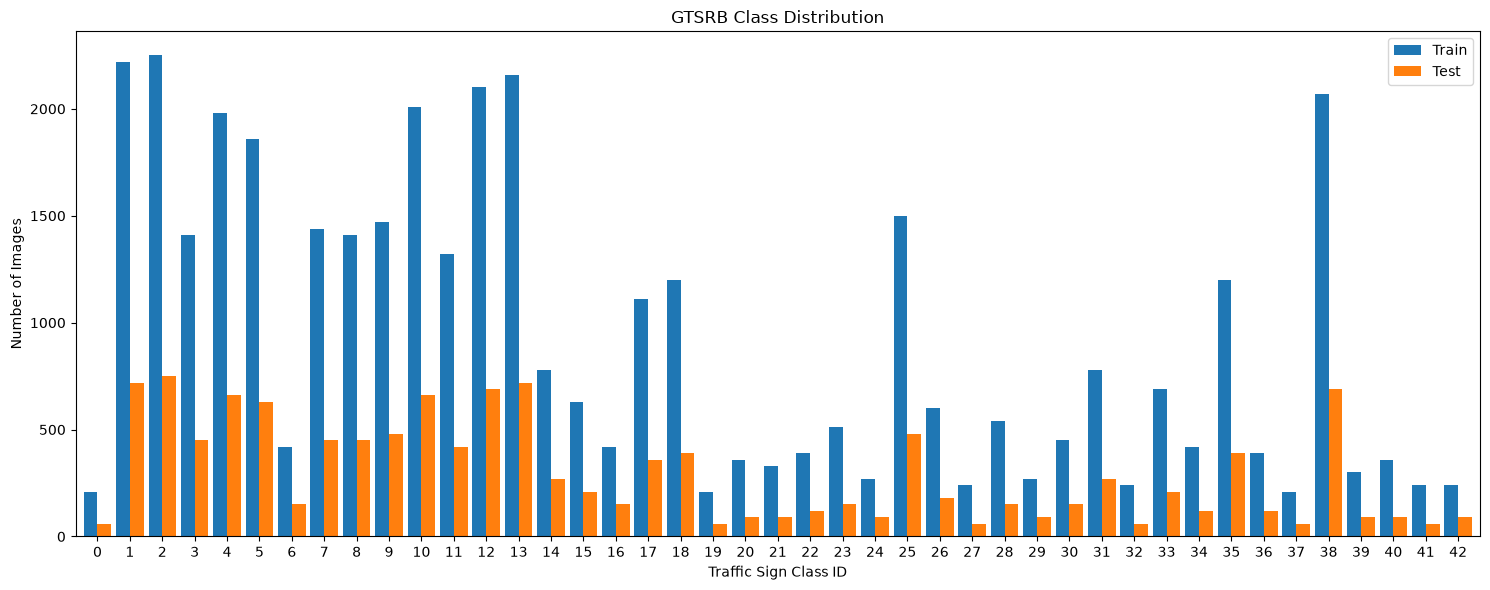

In [ ]:
# ======================================
# 7. Class Distribution Analysis
# ======================================

train_counts = train_df["ClassId"].value_counts().sort_index()
test_counts = test_df["ClassId"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "ClassId": range(43)
})

class_distribution["Train"] = (
    class_distribution["ClassId"]
    .map(train_counts)
    .fillna(0)
    .astype(int)
)

class_distribution["Test"] = (
    class_distribution["ClassId"]
    .map(test_counts)
    .fillna(0)
    .astype(int)
)

class_distribution["Total"] = (
    class_distribution["Train"] +
    class_distribution["Test"]
)

display(class_distribution)

class_distribution.to_csv(
    tables_dir / "class_distribution.csv",
    index=False
)

# Plot class distribution
ax = class_distribution.plot(
    x="ClassId",
    y=["Train", "Test"],
    kind="bar",
    figsize=(15, 6),
    width=0.85
)

ax.set_title("GTSRB Class Distribution")
ax.set_xlabel("Traffic Sign Class ID")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    figures_dir / "class_distribution.png",
    dpi=300
)

plt.show()

### 8. Descriptive Statistics of Image Dimensions

In [ ]:
# ======================================
# 8. Final Dataset Statistics
# ======================================

labeled_df = pd.concat(
    [train_df, test_df],
    ignore_index=True
).copy()

labeled_df["AspectRatio"] = (
    labeled_df["Width"] / labeled_df["Height"]
)

final_stats = labeled_df[
    ["Width", "Height", "AspectRatio"]
].agg(["mean", "median", "std", "min", "max"])

print("Final GTSRB Image Statistics:")
display(final_stats.round(3))

final_stats.to_csv(
    tables_dir / "final_image_statistics.csv"
)

# Class imbalance statistics
print("Number of classes:", train_df["ClassId"].nunique())
print("Most frequent training class:", train_counts.idxmax())
print("Maximum training samples:", train_counts.max())
print("Minimum training samples:", train_counts.min())
print(
    "Imbalance ratio:",
    round(train_counts.max() / train_counts.min(), 2)
)


Final GTSRB Image Statistics:


,Width,Height,AspectRatio
mean,50.756,50.338,1.006
median,43.000,43.000,1.000
std,24.500,23.259,0.073
min,25.000,25.000,0.368
max,266.000,232.000,1.438


Number of classes: 43
Most frequent training class: 2
Maximum training samples: 2250
Minimum training samples: 210
Imbalance ratio: 10.71


### 9.Attribute–Target Association Analysis

In [ ]:
# ======================================
# 9. Attribute–Target Association Analysis
# ======================================
correlation_df = train_df.copy()

correlation_df["AspectRatio"] = (
    correlation_df["Width"] /
    correlation_df["Height"]
)

def correlation_ratio(categories, values):
    data = pd.DataFrame({
        "category": categories,
        "value": values
    }).dropna()

    overall_mean = data["value"].mean()

    grouped = data.groupby("category")["value"]

    between_variance = sum(
        len(group) * (group.mean() - overall_mean) ** 2
        for _, group in grouped
    )

    total_variance = (
        (data["value"] - overall_mean) ** 2
    ).sum()

    if total_variance == 0:
        return 0.0

    return np.sqrt(between_variance / total_variance)

attributes = ["Width", "Height", "AspectRatio"]

correlation_results = pd.DataFrame({
    "Attributes' pairs": [
        f"{attribute} – ClassId"
        for attribute in attributes
    ],
    "Correlation coefficient (η)": [
        correlation_ratio(
            correlation_df["ClassId"],
            correlation_df[attribute]
        )
        for attribute in attributes
    ]
})

display(correlation_results.round(4))

correlation_results.to_csv(
    tables_dir / "attribute_target_association.csv",
    index=False
)

,Attributes' pairs,Correlation coefficient (η)
0,Width – ClassId,0.3205
1,Height – ClassId,0.2739
2,AspectRatio – ClassId,0.5671


### 10. Visualize Samples from 43 Classes

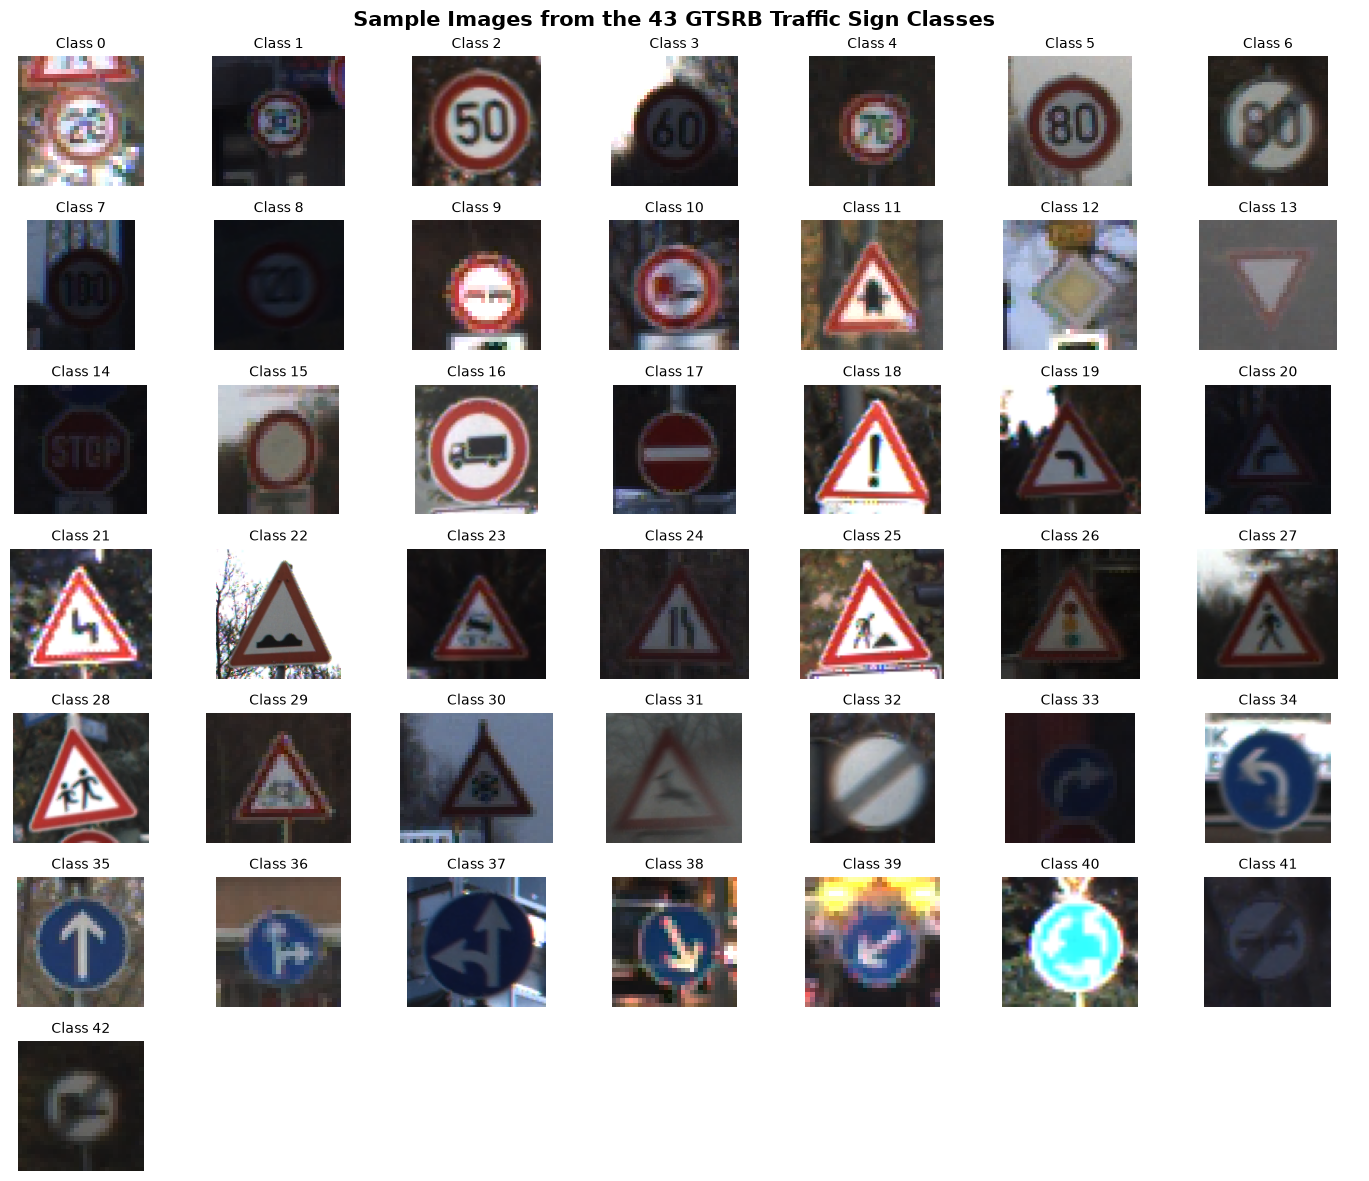

In [ ]:
# ======================================
# 10. Visualize GTSRB Traffic Sign Classes
# ======================================

import matplotlib.pyplot as plt
from PIL import Image
import math

# Select one training image per class
samples = (
    train_df.groupby("ClassId", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("ClassId")
)

# Create a grid of sample images
n_cols = 7
n_rows = math.ceil(len(samples) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 12)
)

axes = axes.flatten()

for i, (_, row) in enumerate(samples.iterrows()):

    image_path = dataset_path / row["Path"]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Class {row['ClassId']}",
        fontsize=10
    )
    axes[i].axis("off")

# Hide unused cells
for j in range(len(samples), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Sample Images from the 43 GTSRB Traffic Sign Classes",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Save figure for the report
plt.savefig(
    figures_dir / "gtsrb_class_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()